# 1. Título

## Sífilis em gestantes e sífilis congênita em Minas Gerais

DCC011 — Introdução a Banco de Dados — Trabalho Prático

# 2. Membros

| Nome | Matrícula |
|---|---|
| Cayo Cesar |2024001674|
| Thales Hungria | 2024001690 |
| Yago Santos | 2023095586 |

# 3. Descrição dos dados

## 3.1 Obtenção dos dados

Usamos os dados de sífilis do Sinan publicados pela Secretaria de Estado de Saúde de Minas Gerais (SES-MG) no portal de dados abertos: https://dados.mg.gov.br/dataset/sifilis

Para obter os dados, basta acessar o portal e baixar dois arquivos CSV:
- **Dados de Sífilis Gestante** (`dados_sifilis_gestante.csv`)
- **Dados Sífilis Congênita** (`dados_sifilis_congenita.csv`)

Os arquivos foram baixados em 21/10/2026.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')



Mounted at /content/drive


In [ ]:
import os
import sqlite3
import pandas as pd

os.chdir("/content/drive/MyDrive/Trabalho IBD")

## 3.2 Leitura dos arquivos

Os arquivos usam `;` como separador. Lemos todas as colunas como texto para não perder nenhuma informação.

In [ ]:
gest = pd.read_csv("dados_sifilis_gestante.csv", sep=";", encoding="utf-8-sig", dtype=str)
cong = pd.read_csv("dados_sifilis_congenita.csv", sep=";", encoding="utf-8-sig", dtype=str)

print("Gestante:", gest.shape[0], "linhas e", gest.shape[1], "colunas")
print("Congênita:", cong.shape[0], "linhas e", cong.shape[1], "colunas")
print("Total:", len(gest) + len(cong), "notificações")
gest.head()

Gestante: 69511 linhas e 14 colunas
Congênita: 34904 linhas e 16 colunas
Total: 104415 notificações


,id_agravo,dt_notific,nu_ano,id_municip,id_regiona,dt_diag,dt_nasc,nu_idade_n,cs_raca,cs_escol_n,id_mn_resi,id_rg_resi,tpesquema,tratparc
0,O981,2017-08-07,2017,SÃO FRANCISCO,JANUÁRIA,2017-08-01,1981-10-21,35,Parda,4ª série completa EF,SÃO FRANCISCO,JANUÁRIA,Penicilina G benzatina 2.400.000UI,Não
1,O981,2024-10-15,2024,VIÇOSA,PONTE NOVA,2024-06-04,2002-07-26,21,Parda,Ensino fundamental completo,VIÇOSA,PONTE NOVA,Penicilina G benzatina 7.200.000UI,Não
2,O981,2024-10-17,2024,ARAPONGA,PONTE NOVA,2024-10-17,1999-03-11,25,Branca,Ensino médio completo,ARAPONGA,PONTE NOVA,Penicilina G benzatina 2.400.000UI,Sim
3,O981,2011-10-20,2011,PARAGUAÇU,AFENAS,2011-10-11,1990-07-17,21,Branca,5ª a 8ª série incompleta do EF,PARAGUAÇU,NaN,Penicilina G benzatina 2.400.000UI,Ignorado
4,O981,2019-03-07,2019,MONTES CLAROS,MONTES CLAROS,2019-03-03,1994-04-04,24,Parda,Ensino médio completo,MONTES CLAROS,MONTES CLAROS,Penicilina G benzatina 4.800.000UI,NaN


In [ ]:
# Quantidade de valores vazios em cada coluna
pd.DataFrame({"gestante": gest.isna().sum(), "congenita": cong.isna().sum()})

,gestante,congenita
antsifil_n,NaN,1.0
cs_escol_n,4863.0,NaN
cs_raca,420.0,510.0
cs_sexo,NaN,1435.0
dt_diag,0.0,0.0
dt_nasc,652.0,2.0
dt_notific,0.0,0.0
evolucao,NaN,0.0
id_agravo,0.0,0.0
id_mn_resi,1.0,2.0


## 3.3 Normalização

Juntamos os dois arquivos em uma única tabela de notificações. Em seguida, separamos as informações que se repetem em tabelas próprias:

- **Agravo:** o código do agravo (O981 = sífilis em gestante, A509 = sífilis congênita) se repete em todas as linhas e foi para a tabela `agravo`.
- **Categoria de tratamento:** os valores de esquema terapêutico (`tpesquema` nas gestantes e `tra_esquem` na congênita) foram para a tabela `categoria_tratamento`, guardando de qual campo cada valor veio.
- **Localidade:** cada notificação tem um município/regional de **notificação** e um de **residência**. Os pares município–regional foram para a tabela `localidade`. A ligação entre notificação e localidade é **M:N** e fica na tabela `notificacao_localidade`, que indica se o local é de notificação, de residência ou os dois.
- **Notificação:** cada linha dos arquivos virou uma notificação com um identificador próprio (`id_notificacao`), porque os arquivos não têm uma chave.

Outras decisões:
- A coluna `nu_ano` foi removida, porque o ano pode ser obtido da data de notificação.
- Quando a regional está vazia, usamos o valor "NÃO INFORMADA".
- Escolaridade e tratamento do parceiro só existem para gestantes, e evolução só existe para a congênita. Nas outras linhas, essas colunas ficam vazias (`NULL`).
- Não fizemos ligação entre gestante e criança, porque os arquivos não permitem isso.

In [ ]:
# Passo 1: juntar os dois arquivos em uma única tabela
gest["campo_origem"] = "tpesquema"
gest["tratamento"] = gest["tpesquema"]
cong["campo_origem"] = "tra_esquem"
cong["tratamento"] = cong["tra_esquem"]

dados = pd.concat([gest, cong], ignore_index=True)
dados["id_notificacao"] = dados.index + 1

# Idade: no arquivo da congênita vem com vírgula ("0,0")
dados["idade"] = pd.to_numeric(dados["nu_idade_n"].str.replace(",", "."), errors="coerce")

# Regional vazia
dados["id_regiona"] = dados["id_regiona"].fillna("NÃO INFORMADA")
dados["id_rg_resi"] = dados["id_rg_resi"].fillna("NÃO INFORMADA")

print("Total de notificações:", len(dados))

Total de notificações: 104415


In [ ]:
# Passo 2: criar as tabelas

# Tabela agravo
agravo = pd.DataFrame({
    "id_agravo": [1, 2],
    "codigo": ["O981", "A509"],
    "denominacao": ["Sífilis em gestante", "Sífilis congênita"],
})
dados["id_agravo_fk"] = dados["id_agravo"].map({"O981": 1, "A509": 2})

# Tabela categoria_tratamento
categoria = dados[["campo_origem", "tratamento"]].dropna().drop_duplicates().reset_index(drop=True)
categoria["id_categoria"] = categoria.index + 1
dados = dados.merge(categoria, on=["campo_origem", "tratamento"], how="left")
categoria = categoria.rename(columns={"tratamento": "descricao"})

# Tabela localidade (pares município-regional de notificação e de residência)
local_notif = dados[["id_notificacao", "id_municip", "id_regiona"]].copy()
local_notif.columns = ["id_notificacao", "municipio", "regional"]
local_notif["tipo"] = "notificacao"

local_resid = dados[["id_notificacao", "id_mn_resi", "id_rg_resi"]].copy()
local_resid.columns = ["id_notificacao", "municipio", "regional"]
local_resid["tipo"] = "residencia"

locais = pd.concat([local_notif, local_resid]).dropna(subset=["municipio"])

localidade = locais[["municipio", "regional"]].drop_duplicates().reset_index(drop=True)
localidade["id_localidade"] = localidade.index + 1

# Tabela notificacao_localidade (relacionamento M:N)
locais = locais.merge(localidade, on=["municipio", "regional"])
locais["eh_notificacao"] = (locais["tipo"] == "notificacao").astype(int)
locais["eh_residencia"] = (locais["tipo"] == "residencia").astype(int)
notificacao_localidade = locais.groupby(["id_notificacao", "id_localidade"], as_index=False)[["eh_notificacao", "eh_residencia"]].max()

# Tabela notificacao
notificacao = dados[["id_notificacao", "id_agravo_fk", "id_categoria", "dt_notific", "idade",
                     "cs_raca", "cs_escol_n", "tratparc", "evolucao"]]
notificacao = notificacao.rename(columns={
    "id_agravo_fk": "id_agravo",
    "dt_notific": "data_notificacao",
    "cs_raca": "raca_cor",
    "cs_escol_n": "escolaridade",
    "tratparc": "tratamento_parceiro",
})

print("agravo:", len(agravo))
print("categoria_tratamento:", len(categoria))
print("localidade:", len(localidade))
print("notificacao:", len(notificacao))
print("notificacao_localidade:", len(notificacao_localidade))

agravo: 2
categoria_tratamento: 10
localidade: 926
notificacao: 104415
notificacao_localidade: 157931


## 3.4 Criação do banco SQLite

Criamos as tabelas com chaves primárias e estrangeiras e inserimos os dados. Como o enunciado sugere, desligamos a verificação de chaves estrangeiras durante a inserção (`PRAGMA foreign_keys = 0`) e depois conferimos se está tudo certo.

In [ ]:
if os.path.exists("sifilis.db"):
    os.remove("sifilis.db")
con = sqlite3.connect("sifilis.db")

con.executescript("""
CREATE TABLE agravo (
    id_agravo   INTEGER PRIMARY KEY,
    codigo      TEXT,
    denominacao TEXT
);

CREATE TABLE categoria_tratamento (
    id_categoria INTEGER PRIMARY KEY,
    campo_origem TEXT,
    descricao    TEXT
);

CREATE TABLE localidade (
    id_localidade INTEGER PRIMARY KEY,
    municipio     TEXT,
    regional      TEXT
);

CREATE TABLE notificacao (
    id_notificacao      INTEGER PRIMARY KEY,
    id_agravo           INTEGER REFERENCES agravo(id_agravo),
    id_categoria        INTEGER REFERENCES categoria_tratamento(id_categoria),
    data_notificacao    TEXT,
    idade               REAL,
    raca_cor            TEXT,
    escolaridade        TEXT,
    tratamento_parceiro TEXT,
    evolucao            TEXT
);

CREATE TABLE notificacao_localidade (
    id_notificacao INTEGER REFERENCES notificacao(id_notificacao),
    id_localidade  INTEGER REFERENCES localidade(id_localidade),
    eh_notificacao INTEGER,
    eh_residencia  INTEGER,
    PRIMARY KEY (id_notificacao, id_localidade)
);
""")

con.execute("PRAGMA foreign_keys = 0")
agravo.to_sql("agravo", con, if_exists="append", index=False)
categoria.to_sql("categoria_tratamento", con, if_exists="append", index=False)
localidade.to_sql("localidade", con, if_exists="append", index=False)
notificacao.to_sql("notificacao", con, if_exists="append", index=False)
notificacao_localidade.to_sql("notificacao_localidade", con, if_exists="append", index=False)
con.commit()
con.execute("PRAGMA foreign_keys = 1")

print("Erros de chave estrangeira:", con.execute("PRAGMA foreign_key_check").fetchall())

Erros de chave estrangeira: []


## 3.5 Conferência dos dados

Contamos as linhas de cada tabela e comparamos com os números da proposta. A quantidade atual é um pouco maior porque a SES-MG atualizou os arquivos depois da entrega da proposta (agora as notificações vão até outubro de 2026).

In [ ]:
contagem = pd.read_sql("""
SELECT 'notificacao' AS tabela, COUNT(*) AS linhas FROM notificacao
UNION ALL SELECT 'agravo', COUNT(*) FROM agravo
UNION ALL SELECT 'localidade', COUNT(*) FROM localidade
UNION ALL SELECT 'categoria_tratamento', COUNT(*) FROM categoria_tratamento
UNION ALL SELECT 'notificacao_localidade', COUNT(*) FROM notificacao_localidade
""", con)
contagem["proposta"] = [102807, 2, 923, 10, 155537]
contagem

,tabela,linhas,proposta
0,notificacao,104415,102807
1,agravo,2,2
2,localidade,926,923
3,categoria_tratamento,10,10
4,notificacao_localidade,157931,155537


In [ ]:
# Primeiras linhas de cada tabela
for tabela in ["agravo", "categoria_tratamento", "localidade", "notificacao", "notificacao_localidade"]:
    display(pd.read_sql(f"SELECT * FROM {tabela} LIMIT 5", con))

,id_agravo,codigo,denominacao
0,1,O981,Sífilis em gestante
1,2,A509,Sífilis congênita


,id_categoria,campo_origem,descricao
0,1,tpesquema,Penicilina G benzatina 2.400.000UI
1,2,tpesquema,Penicilina G benzatina 7.200.000UI
2,3,tpesquema,Penicilina G benzatina 4.800.000UI
3,4,tpesquema,Outro esquema
4,5,tpesquema,Não realizado


,id_localidade,municipio,regional
0,1,SÃO FRANCISCO,JANUÁRIA
1,2,VIÇOSA,PONTE NOVA
2,3,ARAPONGA,PONTE NOVA
3,4,PARAGUAÇU,AFENAS
4,5,MONTES CLAROS,MONTES CLAROS


,id_notificacao,id_agravo,id_categoria,data_notificacao,idade,raca_cor,escolaridade,tratamento_parceiro,evolucao
0,1,1,1,2017-08-07,35.0,Parda,4ª série completa EF,Não,None
1,2,1,2,2024-10-15,21.0,Parda,Ensino fundamental completo,Não,None
2,3,1,1,2024-10-17,25.0,Branca,Ensino médio completo,Sim,None
3,4,1,1,2011-10-20,21.0,Branca,5ª a 8ª série incompleta do EF,Ignorado,None
4,5,1,3,2019-03-07,24.0,Parda,Ensino médio completo,None,None


,id_notificacao,id_localidade,eh_notificacao,eh_residencia
0,1,1,1,1
1,2,2,1,1
2,3,3,1,1
3,4,4,1,0
4,4,812,0,1


# 4. Diagrama ER

**Entidades:**
- **Notificação**: id_notificacao, data_notificacao, idade, raca_cor, escolaridade, tratamento_parceiro, evolucao
- **Agravo**: id_agravo, codigo, denominacao
- **Localidade**: id_localidade, municipio, regional
- **Categoria de tratamento**: id_categoria, campo_origem, descricao

**Relacionamentos:**
- **Agravo — Notificação (1:N):** cada notificação é de um agravo, e um agravo tem várias notificações.
- **Categoria de tratamento — Notificação (1:N):** cada notificação tem no máximo uma categoria de tratamento, e uma categoria aparece em várias notificações.
- **Notificação — Localidade (M:N):** uma notificação está ligada a um local de notificação e a um local de residência, e cada localidade aparece em várias notificações. O relacionamento tem dois atributos: `eh_notificacao` e `eh_residencia`.

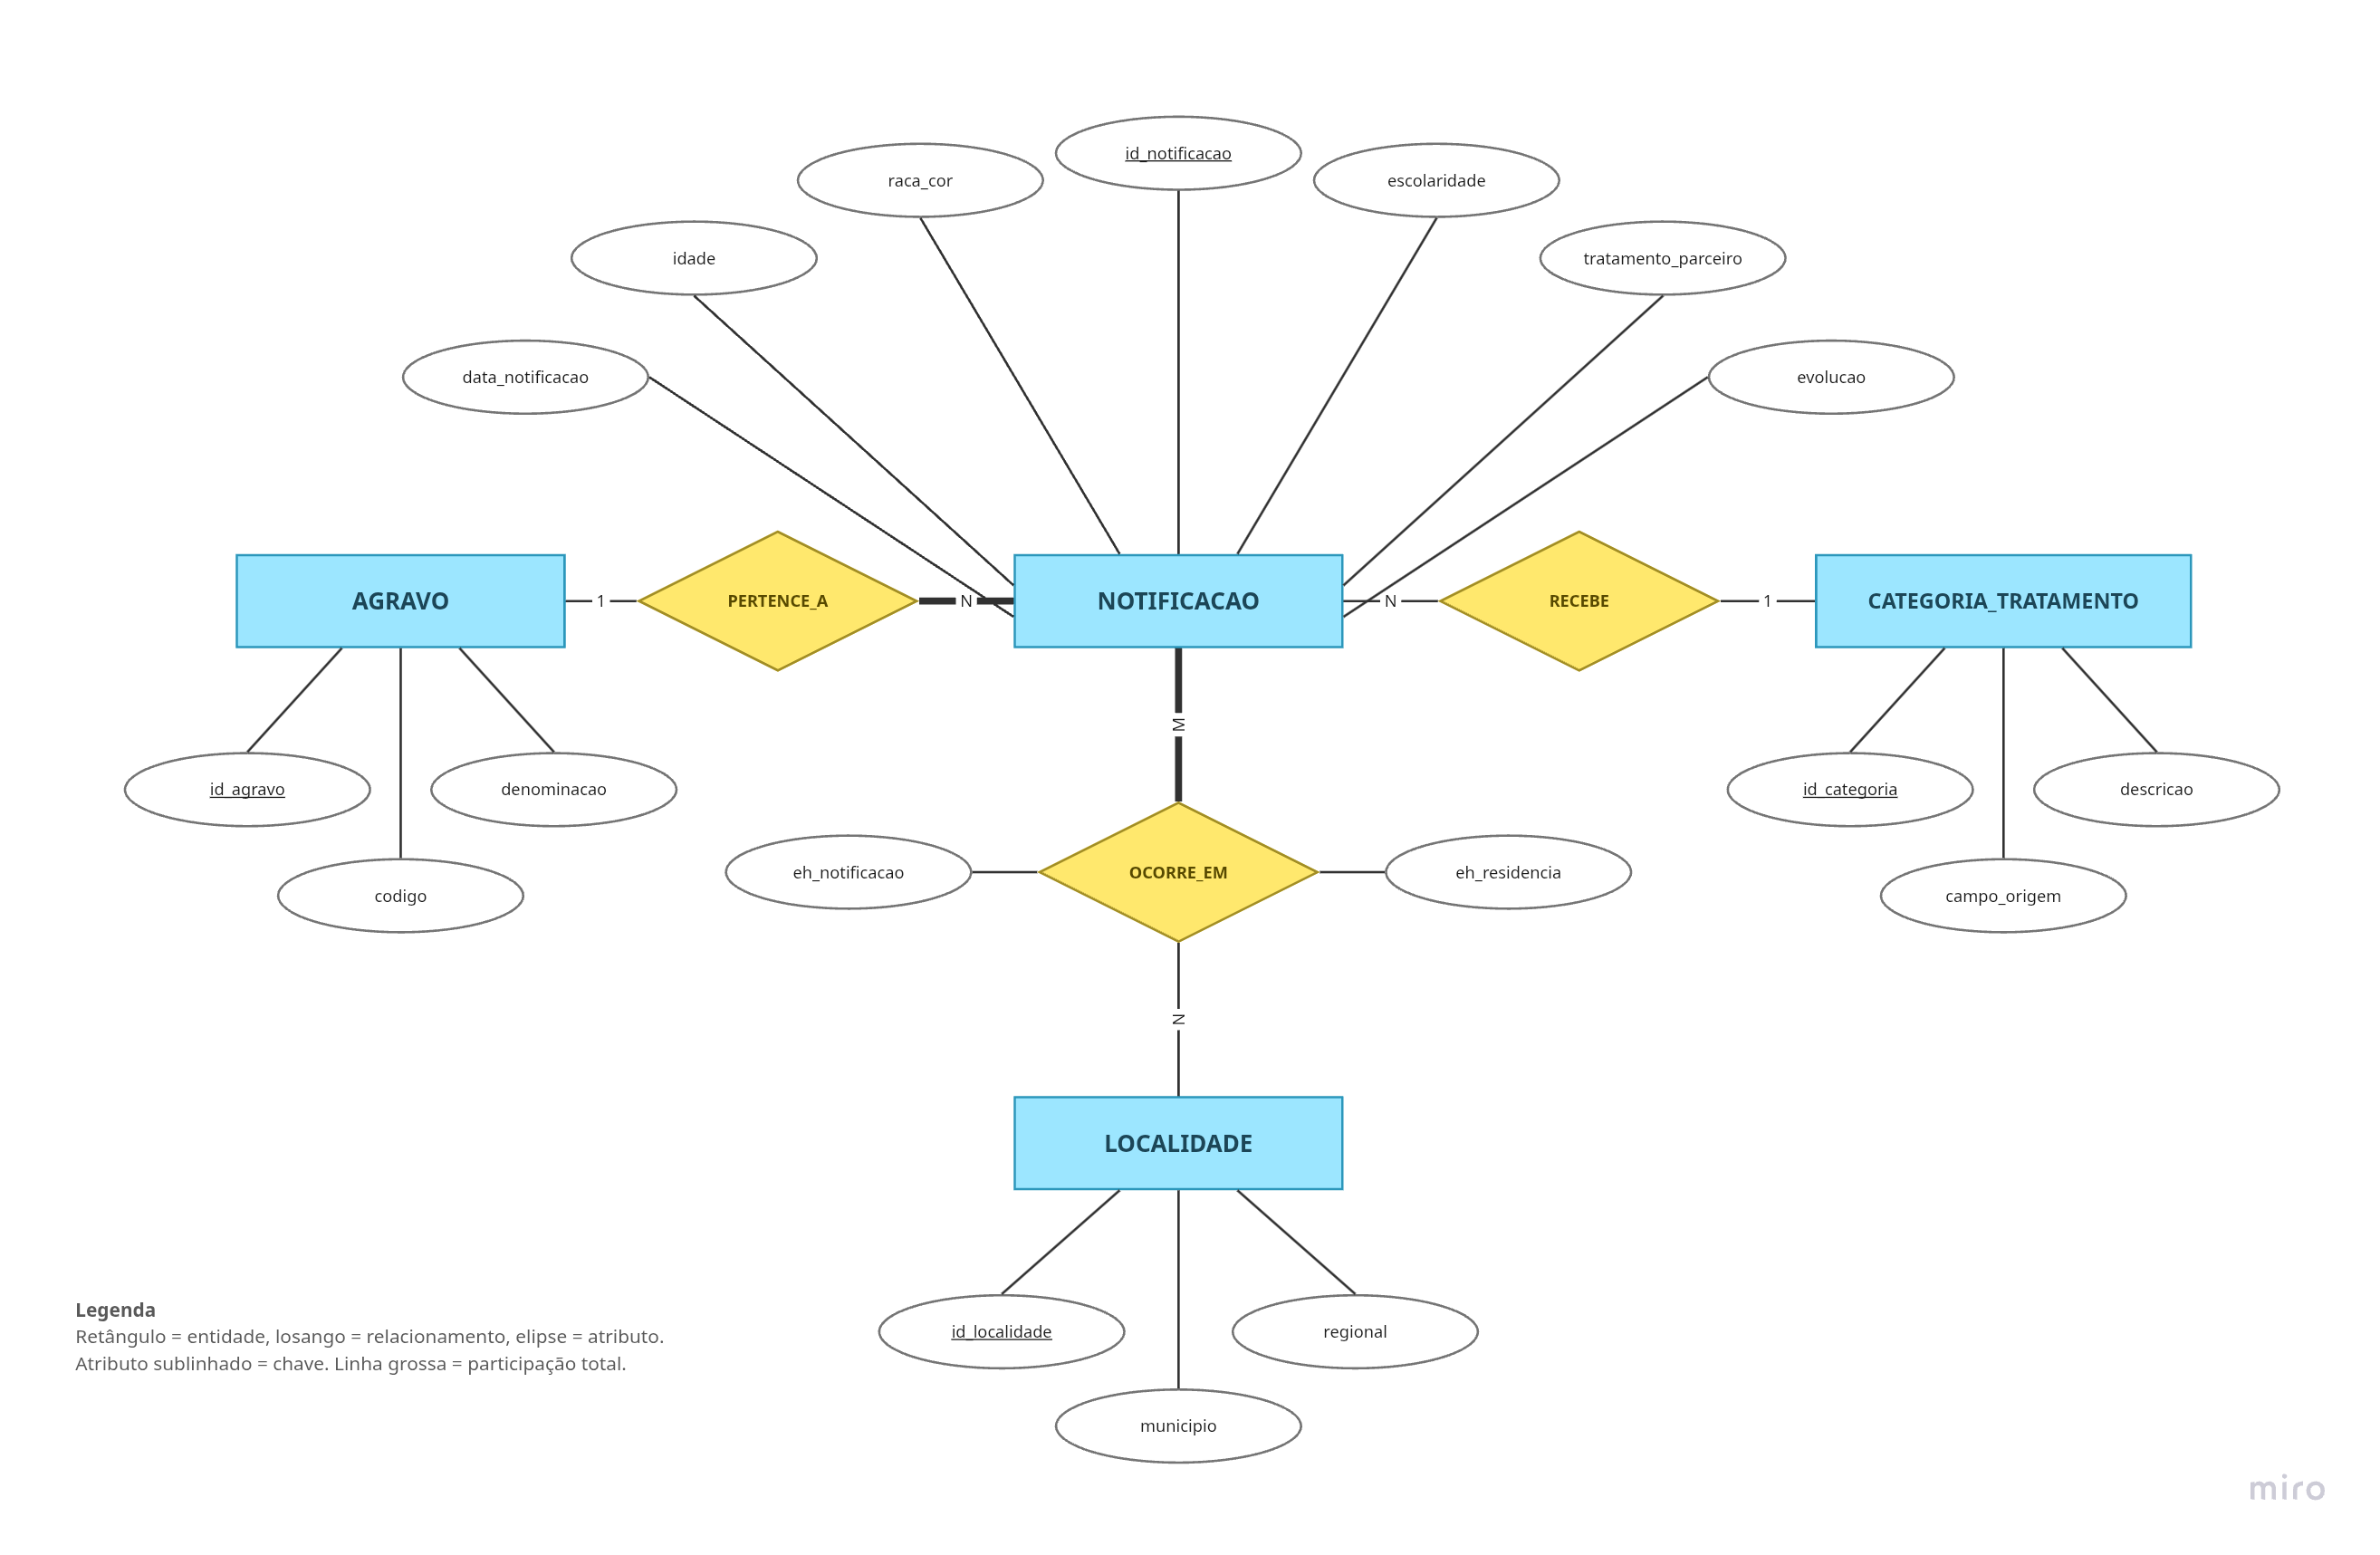

# 5. Diagrama relacional

Cada entidade virou uma tabela. Os relacionamentos 1:N viraram chaves estrangeiras na tabela `notificacao`, e o relacionamento M:N virou a tabela `notificacao_localidade`.



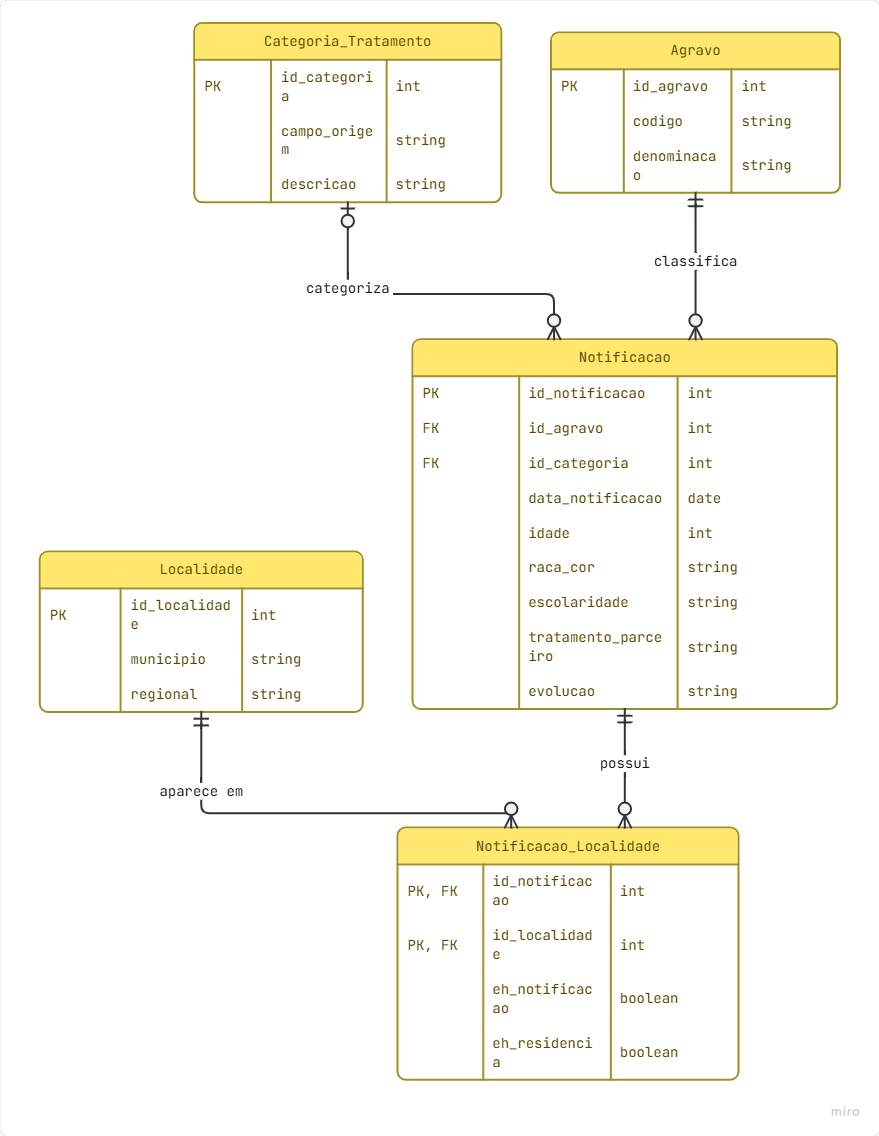